In [1]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import random
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from collections import deque
import random
import math
from collections import namedtuple
import time


In [2]:
print(f"Is MPS (Metal Performance Shader) built? {torch.backends.mps.is_built()}")
print(f"Is MPS available? {torch.backends.mps.is_available()}")

Is MPS (Metal Performance Shader) built? True
Is MPS available? True


In [3]:
#Hyperparameters
INPUT_CHANNELS = 3  
OUTPUT_SIZE = 5  # Number of actions the pacman can take
BATCH_SIZE = 128  # Number of samples to take from the replay memory : best choice is 128
GAMMA = 0.999  # Discount factor

EPS_START = 0.9 # Epsilon greedy strategy
EPS_END = 0.1
EPS_DECAY = 700000 # plus c'est grand plus epsilon decroit lentement

learning_rate = 1e-4

Transition = namedtuple('Transition',('state', 'action', 'next_state', 'reward'))



In [4]:
class CNN(nn.Module):
    def __init__(self, input_channels, output_size): #input channels = 3 if RGB image, 1 if grayscale
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(INPUT_CHANNELS, 32, kernel_size=4, stride=4, padding=1) 
        self.pool = nn.MaxPool2d(kernel_size=4, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=1)
        self.fc1 = nn.Linear(384, OUTPUT_SIZE)                                          
       
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = x.reshape(x.shape[0], -1)
        x = self.fc1(x)
        
        return x

In [5]:
class DQN(nn.Module):
    def __init__(self):
        super(DQN, self).__init__()
        self.model = CNN(INPUT_CHANNELS, OUTPUT_SIZE) 
        self.optimizer = optim.Adam(self.model.parameters(), learning_rate)
        self.criterion = nn.MSELoss()

        # Move the model to my GPU
        self.to(torch.device("mps"))

    def select_action(self, state, epsilon):
        state = torch.tensor(state, dtype=torch.float32).to(torch.device("mps"))  # Move to GPU
        # Epsilon-greedy action selection
        #print("state shape is ", state.shape)
        #print("state is ", state)

        if random.random() > epsilon:
            with torch.no_grad():
                q_values = self.model(state)
                # softmax pour avoir une distribution de proba
                #q_values = F.softmax(q_values, dim=1)
                #action = torch.multinomial(q_values, 1).item()
                #print("q_values is ", q_values)
                #print("action is ", action)
                action = torch.argmax(q_values).item()
        else:
            action = random.randint(0, OUTPUT_SIZE-1)
            
        return action


    def optimize_model(self, memory):
        # Get a batch of experiences from memory
        if len(memory) < BATCH_SIZE:
            return
        #start_total_time = time.time()
        transitions = memory.sample(BATCH_SIZE)
        batch = Transition(*zip(*transitions))

        state_batch = torch.cat(batch.state).to(torch.device("mps"))  # Move to GPU
        action_batch = torch.cat([torch.tensor([a]) for a in batch.action]).to(torch.device("mps"))
        reward_batch = torch.cat(batch.reward).to(torch.device("mps"))
        next_state_batch = torch.cat(batch.next_state).to(torch.device("mps"))

        # Compute Q(s_t, a) - the model computes Q(s_t), then we select the columns of actions taken
        state_action_values = self.model(state_batch).gather(1, action_batch.unsqueeze(1))

        # Compute V(s_{t+1}) for all next states.
        next_state_values = self.model(next_state_batch).max(1)[0].detach()
        # bellman equation
        expected_state_action_values = (next_state_values * GAMMA) + reward_batch

        # Compute Huber loss
        loss = self.criterion(state_action_values, expected_state_action_values.unsqueeze(1))

        # Optimize the model
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        #end_total_time = time.time()

        #print(f"Execution de optimize_model: {end_total_time-start_total_time}")


In [6]:
class ReplayMemory(object):
    def __init__(self, capacity):
        self.memory = deque([],maxlen=capacity)

    def push(self, *args):
        self.memory.append(Transition(*args))

    def sample(self, batch_size):
        return random.sample(self.memory, batch_size)

    def __len__(self):
        return len(self.memory)


In [7]:
def preprocess_observation(observation):
  
    observation_array = np.array(observation[0])  # on stock le tableau numpy dans observation et le dictionnaire dans info
    
    # crop the obsservation height 210 -> 160
    observation = observation[:172, :, :]

    # take only 1/2 pixels of observation
    observation = observation[::2, ::2, :]
    
    # Convert the observation to grayscale
    # observation = np.mean(observation, axis=2)
    # Normalize the observation to the range [0, 1] so that it is accepted by the CNN
    observation = observation / 255.0

    # Resize the observation to the expected input size of the CNN
    observation = torch.tensor(observation, dtype=torch.float32).permute(2, 0, 1).unsqueeze(0)
    
    return observation

In [8]:
def pacman_train():
    env = gym.make('ALE/MsPacman-v5')
    memory = ReplayMemory((1000))
    dqn = DQN()

    # Load the agent state if a saved state exists
    # try:
    #     dqn.load_state_dict(torch.load(f"pth_de_pacman_50000/dqn_episode_30000.pth "))
    # except FileNotFoundError:
    #     pass
    
    total_reward_tab = []
    true_total_reward_tab = []

    Samples_true_rewards_plot = []
    nbr_samples = 0

    num_episodes = 30001
    steps_done = 0

    for i_episode in range(num_episodes):
        
        observation, game_state_info = env.reset()
        
        state = preprocess_observation(observation) 
        #print("state is",state.shape)
        #plot_image(state)
        
        total_reward = 0
        true_total_reward = 0
        previous_action_reward = 0

        lives = game_state_info['lives']
        
        done = False

        while not done:
            #start_time_action = time.time()
            epsilon = EPS_END + (EPS_START - EPS_END) * \
                math.exp(-1. * steps_done / EPS_DECAY)
            #print("epsilon is ",epsilon)
            #print("state shape is",state.shape)
            action = dqn.select_action(state, epsilon)
            #print("action is ",action)
            next_observation, reward, terminated, truncated, game_state_info = env.step(action)
            #print(f"true reward is {reward}")
            
            true_total_reward += reward
            
            # If the number of lives has decreased, subtract 50 from the reward
            if game_state_info['lives'] < lives:
                reward -= 50
                lives = game_state_info['lives']
                
            elif reward == previous_action_reward:
                reward -= 1 # penalize the agent for not taking an action pour l'instant on fait pas ca
            elif reward > 10:
                reward = 10

            done = terminated or truncated
            #print(f"reward shaped is {reward}")
            next_state = preprocess_observation(next_observation)
            memory.push(state, action, next_state, torch.tensor([reward], dtype=torch.float32))
            #print memory length

            
            ##### visualisation
            # image = next_state[0]
            # image = image.permute(1, 2, 0)
            # plt.imshow(image)
            # plt.savefig(f"exemple_image_preprocessed.png")
            # plt.show()

            previous_action_reward = reward
            state = next_state

            # check pour optimiser tous les x steps 
            if steps_done % 30 == 0:
                dqn.optimize_model(memory)
                
            steps_done += 1
            
            total_reward += reward
            #end_time_action = time.time()
            #print(f"Execution d'une action {end_time_action-start_time_action}")

        print(f'Episode: {i_episode}, True game Total reward: {true_total_reward}')
        total_reward_tab.append(total_reward)
        true_total_reward_tab.append(true_total_reward)


        if i_episode % 50 == 0:
            torch.save(dqn.state_dict(), f"pth_de_pacman_50000/dqn_episode_{i_episode}.pth")
            Samples_true_rewards_plot.append(true_total_reward)
            nbr_samples += 1
        if i_episode % 100 == 0:
            #plot sliding average of the total rewards
            plt.plot(pd.Series(true_total_reward_tab).rolling(30).mean(), linewidth=0.5, color='red')
            plt.xlabel('Episode')
            plt.ylabel('Total Reward')
            plt.title('Number of episodes {} sliding average'.format(i_episode))
            plt.savefig(f"pth_de_pacman_50000/sliding_average_episode_{i_episode}.png")

            plt.show()

                
                

    env.close()

    # After all episodes are done, plot the total rewards
    plt.scatter(range(num_episodes), true_total_reward_tab, s = 0.1, color='blue')
    # plot a tendancy line to see the evolution of the total reward
    episodes_idx = np.arange(num_episodes)
    sns.regplot(x=episodes_idx, y=true_total_reward_tab, order=1, color='orange')
    
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.title('Number of episodes {}'.format(i_episode))
    plt.savefig("pth_de_pacman_50000/total_reward_qlearning_.png")

    plt.show()

    # plot sliding average of the total rewards
    plt.plot(pd.Series(true_total_reward_tab).rolling(30).mean(), linewidth=0.5, color='red')
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.title('Number of episodes {} sliding average'.format(i_episode))
    plt.savefig("pth_de_pacman_50000/sliding_average_reward_qlearning.png")

    plt.show()


    # Plot the rewards obtained every 50 episodes
    plt.plot(Samples_true_rewards_plot, linewidth=0.5, color='red')
    plt.xlabel('Episode')
    plt.ylabel('Total Reward')
    plt.title('Number of episodes {}'.format(i_episode))
    plt.savefig("pth_de_pacman_50000/total_reward_qlearning_50.png")
    
    plt.show()




In [9]:
def pacman_play():
    # Load the game environment
    env = gym.make('ALE/MsPacman-v5', render_mode='human')  # Adjust the environment ID if necessary.
    
    #memory = ReplayMemory(1000)
    agent = DQN()

    # Choose the appropriate device
    device = torch.device('mps') if torch.backends.mps.is_available() else torch.device('cpu')
    print(f"Using device: {device}")

    try:
        
        agent.load_state_dict(torch.load(f"pth_de_pacman_30000/dqn_episode_30000.pth", map_location=device))

    except FileNotFoundError:
        pass
    
    agent.to(device)  # move on GPU
 
    cnn = CNN(INPUT_CHANNELS, OUTPUT_SIZE)

    observation, game_state_info = env.reset() # Reset the environment for a new episode : ressort le tableau observation + game state info
    state = preprocess_observation(observation) 
    done = False
    score = 0

    while not done:
        action = agent.select_action(state, EPS_END)
        next_observation, reward, terminated, truncated, game_state_info = env.step(action)

        next_state = preprocess_observation(next_observation)

        done = terminated or truncated
        
        score += reward  
        state = next_state
        #if compteur_test == 100: # pour qu'il arrete de bugger
        #    done = True
        #print(f"Score: {score}")
     
    env.close()  # Close the environment
    print(f"c'est bon c'est fini")


In [10]:
if __name__ == '__main__':
    pacman_play()
    #pacman_train()



A.L.E: Arcade Learning Environment (version 0.8.1+53f58b7)
[Powered by Stella]


Using device: mps


ipykernel_1245/2604925151.py:12: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  state = torch.tensor(state, dtype=torch.float32).to(torch.device("mps"))  # Move to GPU


c'est bon c'est fini


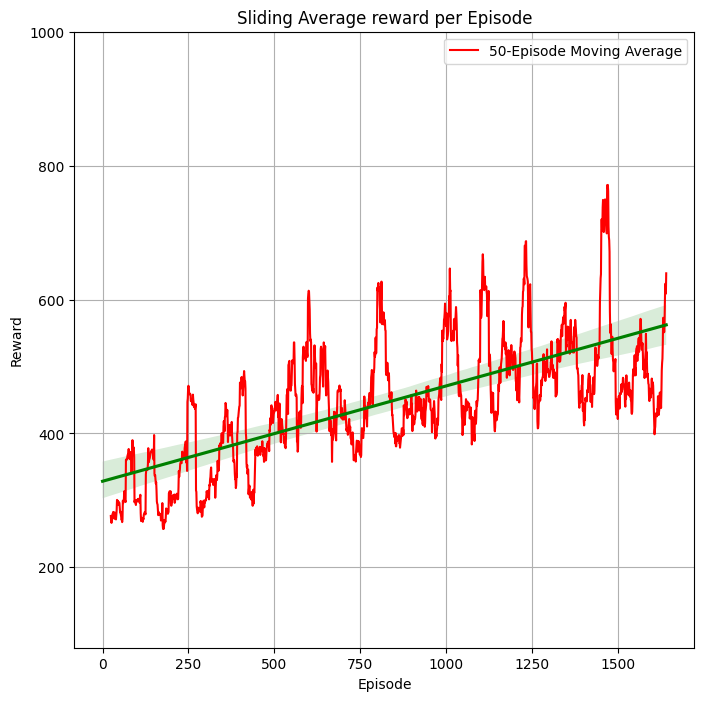

: 

In [11]:
# open the file "output_coab.txt" and read the reward for each episode and plot

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load and process the data from the uploaded file
file_path = 'output_colab.txt'

# Read the content of the file
with open(file_path, 'r') as file:
    lines = file.readlines()

# Extract episode numbers and rewards
episodes = []
rewards = []
for line in lines:
    if "Episode:" in line:
        parts = line.strip().split(',')
        episode = int(parts[0].split(':')[1].strip())
        reward = float(parts[1].split(':')[-1].strip())
        episodes.append(episode)
        rewards.append(reward)

# Convert to DataFrame for easier manipulation
data = pd.DataFrame({
    'Episode': episodes,
    'Reward': rewards
})

# Calculate the sliding window average
window_size = 25
data['Rolling_Mean'] = data['Reward'].rolling(window=window_size).mean()

# Plotting
plt.figure(figsize=(8, 8))
plt.ylim(min(data['Reward']), 1000)
#plt.plot(data['Episode'], data['Reward'], label='Reward')
plt.plot(data['Episode'], data['Rolling_Mean'], label='50-Episode Moving Average', color='red')
# plot a linear regression of the reward
sns.regplot(x=episodes, y=rewards, order=1, color='green', scatter=False)

plt.title('Sliding Average reward per Episode')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.legend()
plt.grid(True)

plt.savefig("training_colab_1750_eps10.png")

plt.show()



